# Notebook 3 — Cross-Event Evaluation

**Student** Xin Yiing · **Group** CrisisLens (36118)

Retrain the winning imbalance arm on both encoders with the held-out event removed, evaluate on the unseen event, and compare calibration and selective prediction between seen and unseen distributions.

## 1 — Setup

In [4]:
# One-time environment setup for Kaggle or fresh venv.
# Uncomment the lines below as needed.

!pip install -q transformers datasets scikit-learn matplotlib seaborn

In [5]:
# Standard library
import os, json, re, warnings, time
from pathlib import Path

# Numeric and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML
import torch
from sklearn.metrics import f1_score, classification_report

# HuggingFace
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
)
from datasets import Dataset

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ── Constants ──
LABELS = [
    "caution_and_advice",
    "displaced_people_and_evacuations",
    "infrastructure_and_utility_damage",
    "injured_or_dead_people",
    "missing_or_found_people",
    "not_humanitarian",
    "other_relevant_information",
    "requests_or_urgent_needs",
    "rescue_volunteering_or_donation_effort",
    "sympathy_and_support",
]
NUM_LABELS = len(LABELS)
LABEL2ID   = {l: i for i, l in enumerate(LABELS)}
ID2LABEL   = {i: l for i, l in enumerate(LABELS)}

HELD_OUT_EVENT = "cyclone_idai_2019"
ENCODERS       = ["distilbert-base-uncased", "cardiffnlp/twitter-roberta-base"]
SEED           = 42
MAX_LEN        = 128

print(f"{'Labels':<20} {NUM_LABELS}")
print(f"{'Held-out event':<20} {HELD_OUT_EVENT}")

Labels               10
Held-out event       cyclone_idai_2019


## 2 — Paths, GPU, and Checkpointing

In [6]:
ON_KAGGLE  = os.path.exists("/kaggle/working")
BASE       = "/kaggle/working" if ON_KAGGLE else "."
OUTPUT_DIR = os.path.join(BASE, "outputs")

RESULTS_DIR = os.path.join(OUTPUT_DIR, "results", "cross_event", "transformer")
LOGITS_DIR  = os.path.join(OUTPUT_DIR, "logits", "transformer")
CKPT_DIR    = os.path.join(OUTPUT_DIR, "checkpoints")
PRED_DIR    = os.path.join(OUTPUT_DIR, "predictions", "transformer")

for d in [RESULTS_DIR, LOGITS_DIR, CKPT_DIR, PRED_DIR]:
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{'Kaggle':<20} {ON_KAGGLE}")
print(f"{'Device':<20} {device}")
if device.type == "cuda":
    print(f"{'GPU':<20} {torch.cuda.get_device_name(0)}")

# ── Stage checkpointing ──
STAGE_FILE = os.path.join(OUTPUT_DIR, "nb3_stages.json")


def stage_done(name):
    if os.path.exists(STAGE_FILE):
        with open(STAGE_FILE) as f:
            return name in json.load(f)
    return False


def mark_done(name):
    stages = {}
    if os.path.exists(STAGE_FILE):
        with open(STAGE_FILE) as f:
            stages = json.load(f)
    stages[name] = True
    with open(STAGE_FILE, "w") as f:
        json.dump(stages, f)
    print(f"  Stage '{name}' marked done")


if os.path.exists(STAGE_FILE):
    with open(STAGE_FILE) as f:
        print(f"Previously completed: {list(json.load(f).keys())}")

Kaggle               True
Device               cuda
GPU                  Tesla T4


## 3 — Load NB1/NB2 Metadata

In [7]:
# find_file — recursive search across several root directories
def find_file(filename, roots):
    for root in roots:
        for hit in Path(root).rglob(filename):
            print(f"  Found {filename} at {hit}")
            return str(hit)
    return None


search_roots = [
    os.path.join(BASE, "models", "transformer"),
    os.path.join(OUTPUT_DIR, "models", "transformer"),
    os.path.join(OUTPUT_DIR, "results", "transformer"),
    os.path.join(BASE, "results", "transformer"),
]
if ON_KAGGLE:
    search_roots.append("/kaggle/input")

metadata_path = find_file("metadata.json", search_roots)
assert metadata_path, "metadata.json not found. Upload humaid-nb1-outputs or nb2 dataset."

with open(metadata_path) as f:
    metadata = json.load(f)

T_frozen   = metadata["temperature_T"]
TAU_frozen = metadata["review_threshold_tau"]
WINNER_IMB = metadata["imbalance_method"]

config_path = find_file("go_no_go_decision.json", search_roots)
assert config_path, "go_no_go_decision.json not found. Upload nb1 outputs dataset."

with open(config_path) as f:
    WINNER_RID = json.load(f)["winner_run_id"]

print(f"{'Winner run':<20} {WINNER_RID}")
print(f"{'Winner imbalance':<20} {WINNER_IMB}")
print(f"{'Frozen T':<20} {T_frozen}")
print(f"{'Frozen tau':<20} {TAU_frozen}")

  Found metadata.json at /kaggle/input/models/lxyroo/humaid-nb1-outputs-for-nb3/other/default/1/metadata.json
  Found go_no_go_decision.json at /kaggle/input/models/lxyroo/humaid-nb1-outputs-for-nb3/other/default/1/go_no_go_decision.json
Winner run           A4
Winner imbalance     plain
Frozen T             1.3509
Frozen tau           0.8945


## 4 — Data Loading

In [8]:
# clean_text — strip URLs, anonymise @mentions, collapse whitespace
def clean_text(text):
    if not isinstance(text, str):
        text = str(text) if text is not None else ""
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"@\w+", "@user", text)
    text = re.sub(r"#", "", text)
    return re.sub(r"\s+", " ", text).strip()


# read_tsv — load one HumAID TSV split
def read_tsv(path):
    df = pd.read_csv(path, sep="\t")
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns={"tweet_text": "text", "class_label": "label"}, errors="ignore")
    df = df.dropna(subset=["text", "label"])
    df["text"] = df["text"].apply(clean_text)
    return df[df["label"].isin(LABELS)].reset_index(drop=True)


# ── Locate event-wise data. Files are named <event>_train.tsv / _dev.tsv / _test.tsv,
# each event's three files sitting together in its own folder. ──
DATA_ROOT_CANDIDATES = [
    "/kaggle/input/datasets/lxyroo/humaid-data-events-set1-47k-tar/events_set1",
    os.path.join(BASE, "data", "raw", "humaid"),
    os.path.join(BASE, "data", "humaid"),
]
if ON_KAGGLE:
    DATA_ROOT_CANDIDATES.append("/kaggle/input")

train_files = []
DATA_DIR = None
for root in DATA_ROOT_CANDIDATES:
    root_path = Path(root)
    if not root_path.exists():
        continue
    found = [f for f in root_path.rglob("*_train.tsv") if not f.name.startswith("._")]
    if found:
        train_files = found
        DATA_DIR = root
        break

assert train_files, (
    f"No <event>_train.tsv found under any of {DATA_ROOT_CANDIDATES}.\n"
    f"Check the HumAID event-wise dataset is attached to this notebook (Add Data)."
)

# ── Load every event: derive event name by stripping the _train.tsv suffix ──
splits = {"train": [], "dev": [], "test": []}
event_names = []

for train_file in sorted(train_files):
    event_name = train_file.name[: -len("_train.tsv")].lower()
    event_names.append(event_name)
    folder = train_file.parent
    for sn in splits:
        tsv = folder / f"{event_name}_{sn}.tsv"
        if tsv.exists():
            df = read_tsv(str(tsv))
            df["event"] = event_name
            splits[sn].append(df)

train_full = pd.concat(splits["train"], ignore_index=True)
val_full   = pd.concat(splits["dev"],   ignore_index=True)
test_full  = pd.concat(splits["test"],  ignore_index=True)

print(f"{'Data source':<25} {DATA_DIR}")
print(f"{'Events found':<25} {len(event_names)}")
print(f"{'Full train':<25} {len(train_full)}")
print(f"{'Full val':<25} {len(val_full)}")
print(f"{'Full test':<25} {len(test_full)}")
assert HELD_OUT_EVENT in event_names, f"'{HELD_OUT_EVENT}' not among loaded events: {sorted(event_names)}"

Data source               /kaggle/input/datasets/lxyroo/humaid-data-events-set1-47k-tar/events_set1
Events found              13
Full train                30381
Full val                  4422
Full test                 8606


### 4.1 — Split by held-out event

In [9]:
# PART 4 step 1 — remove held-out event from train+val, isolate its test set
held_train = train_full["event"].str.contains(HELD_OUT_EVENT, case=False, na=False)
held_val   = val_full["event"].str.contains(HELD_OUT_EVENT, case=False, na=False)
held_test  = test_full["event"].str.contains(HELD_OUT_EVENT, case=False, na=False)

train_xev = train_full[~held_train].reset_index(drop=True)
val_xev   = val_full[~held_val].reset_index(drop=True)
test_held = test_full[held_test].reset_index(drop=True)

assert len(test_held) > 0, f"No test rows for {HELD_OUT_EVENT}. Check event names: {sorted(test_full['event'].unique())}"

unique_events = sorted(train_full["event"].unique())
for ev in unique_events:
    marker = " << HELD OUT" if HELD_OUT_EVENT.lower() in ev.lower() else ""
    print(f"  {ev}{marker}")

print(f"\n{'Train (held-out removed)':<30} {len(train_xev)}")
print(f"{'Val (held-out removed)':<30} {len(val_xev)}")
print(f"{'Test (held-out only)':<30} {len(test_held)}")

  canada_wildfires_2016
  cyclone_idai_2019 << HELD OUT
  ecuador_earthquake_2016
  greece_wildfires_2018
  hurricane_harvey_2017
  hurricane_irma_2017
  hurricane_maria_2017
  hurricane_matthew_2016
  italy_earthquake_aug_2016
  kaikoura_earthquake_2016
  maryland_floods_2018
  puebla_mexico_earthquake_2017
  srilanka_floods_2017

Train (held-out removed)       27628
Val (held-out removed)         4021
Test (held-out only)           779


**4.1 Explanation**

- All data from the held-out event is removed from training and validation.
- The model never sees this event during training, so evaluation on its test set measures generalisation to an unseen disaster.

## 5 — Training Infrastructure

In [10]:
# FocalLoss — focal loss for class imbalance
class FocalLoss(torch.nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, labels):
        ce = torch.nn.functional.cross_entropy(logits, labels, weight=self.alpha, reduction="none")
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


# WeightedCE — cross-entropy with inverse-frequency class weights
class WeightedCE(torch.nn.Module):
    def __init__(self, weights):
        super().__init__()
        self.weights = weights

    def forward(self, logits, labels):
        return torch.nn.functional.cross_entropy(logits, labels, weight=self.weights)


# CustomTrainer — Trainer subclass with pluggable loss
class CustomTrainer(Trainer):
    def __init__(self, *args, loss_fn=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.loss_fn = loss_fn

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = self.loss_fn(outputs.logits, labels) if self.loss_fn else torch.nn.functional.cross_entropy(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss


print("FocalLoss, WeightedCE, CustomTrainer defined")

FocalLoss, WeightedCE, CustomTrainer defined


## 6 — Regime B Training

In [11]:
# run_regime_b — train one encoder with the held-out event removed
def run_regime_b(encoder_name, imbalance, train_df, val_df, seed=42):
    run_id = f"B_{encoder_name.split('/')[-1]}_{imbalance}_s{seed}"
    ckpt_path = os.path.join(CKPT_DIR, f"{run_id}_best")

    if stage_done(run_id):
        print(f"  Skipping {run_id} (already done)")
        return run_id

    print(f"\n{'='*60}\n  Training: {run_id}\n{'='*60}")
    torch.manual_seed(seed)
    np.random.seed(seed)

    tokenizer = AutoTokenizer.from_pretrained(encoder_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        encoder_name, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID,
    ).to(device)

    def tokenize(df):
        enc = tokenizer(df["text"].tolist(), truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="np")
        return Dataset.from_dict({"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"], "labels": df["label"].map(LABEL2ID).values})

    train_ds, val_ds = tokenize(train_df), tokenize(val_df)

    loss_fn = None
    if imbalance == "class_weighted":
        counts = train_df["label"].value_counts()
        w = torch.tensor([1.0 / counts.get(l, 1) for l in LABELS], dtype=torch.float32).to(device)
        loss_fn = WeightedCE(w / w.sum() * NUM_LABELS)
    elif imbalance == "focal":
        loss_fn = FocalLoss(gamma=2.0)

    def compute_metrics(eval_pred):
        return {"macro_f1": f1_score(eval_pred[1], np.argmax(eval_pred[0], axis=1), average="macro")}

    args = TrainingArguments(
        output_dir=os.path.join(CKPT_DIR, run_id),
        num_train_epochs=5, per_device_train_batch_size=32, per_device_eval_batch_size=64,
        learning_rate=2e-5, warmup_ratio=0.1, weight_decay=0.01,
        eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
        seed=seed, fp16=torch.cuda.is_available(), report_to="none", logging_steps=50,
    )

    trainer = CustomTrainer(
        model=model, args=args, loss_fn=loss_fn,
        train_dataset=train_ds, eval_dataset=val_ds,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )

    t0 = time.time()
    trainer.train()
    print(f"  Val macro-F1: {trainer.evaluate()['eval_macro_f1']:.4f}  ({(time.time()-t0)/60:.1f} min)")

    trainer.save_model(ckpt_path)
    tokenizer.save_pretrained(ckpt_path)
    mark_done(run_id)
    return run_id


# ── Train both encoders ──
regime_b_runs = {}
for enc in ENCODERS:
    regime_b_runs[enc] = run_regime_b(enc, WINNER_IMB, train_xev, val_xev, seed=SEED)

print(f"\nRegime B runs: {regime_b_runs}")


  Training: B_distilbert-base-uncased_plain_s42


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

  Val macro-F1: 0.7673  (29.3 min)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Stage 'B_twitter-roberta-base_plain_s42' marked done

Regime B runs: {'distilbert-base-uncased': 'B_distilbert-base-uncased_plain_s42', 'cardiffnlp/twitter-roberta-base': 'B_twitter-roberta-base_plain_s42'}


## 7 — Inference on Held-Out Event

In [12]:
# predict_on_set — batch inference, returns logits and integer labels
def predict_on_set(run_id, test_df):
    ckpt = os.path.join(CKPT_DIR, f"{run_id}_best")
    tokenizer = AutoTokenizer.from_pretrained(ckpt)
    model = AutoModelForSequenceClassification.from_pretrained(ckpt).to(device)
    model.eval()

    enc = tokenizer(test_df["text"].tolist(), truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt")
    all_logits = []
    with torch.no_grad():
        for i in range(0, len(test_df), 64):
            batch = {k: v[i:i+64].to(device) for k, v in enc.items()}
            all_logits.append(model(**batch).logits.cpu().numpy())

    return np.concatenate(all_logits), test_df["label"].map(LABEL2ID).values


results_b = {}
for enc in ENCODERS:
    rid = regime_b_runs[enc]
    short = enc.split("/")[-1]
    logits, labels = predict_on_set(rid, test_held)

    np.save(os.path.join(LOGITS_DIR, f"{rid}_held_logits.npy"), logits)
    np.save(os.path.join(LOGITS_DIR, f"{rid}_held_labels.npy"), labels)

    macro_f1 = f1_score(labels, logits.argmax(axis=1), average="macro")
    results_b[short] = {"run_id": rid, "held_macro_f1": round(float(macro_f1), 4), "n": len(labels)}
    print(f"  {short:<30} F1={macro_f1:.4f}  (n={len(labels)})")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  distilbert-base-uncased        F1=0.6969  (n=779)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  twitter-roberta-base           F1=0.7182  (n=779)


## 8 — Seen vs Unseen Comparison

In [26]:
# PART 8 — load NB1 seen-test logits and compare with unseen held-out
# Actual filenames carry a seed suffix (e.g. A4_s123_test_logits.npy) that the
# short winner_run_id ("A4") doesn't include, so match by prefix instead of exact name.
def find_by_prefix(prefix, suffix, roots):
    for root in roots:
        root_path = Path(root)
        if not root_path.exists():
            continue
        hits = sorted(root_path.rglob(f"{prefix}*{suffix}"))
        if hits:
            print(f"  Found {hits[0].name} at {hits[0]}")
            return str(hits[0])
    return None


search_roots = [LOGITS_DIR] + (["/kaggle/input"] if ON_KAGGLE else [])
seen_logits_path = find_by_prefix(WINNER_RID, "_test_logits.npy", search_roots)
seen_labels_path = find_by_prefix(WINNER_RID, "_test_labels.npy", search_roots)
assert seen_logits_path and seen_labels_path, f"Cannot find {WINNER_RID}*_test_logits/labels.npy under {search_roots}"

seen_logits = np.load(seen_logits_path)
seen_labels = np.load(seen_labels_path)
seen_preds  = seen_logits.argmax(axis=1)
seen_f1     = f1_score(seen_labels, seen_preds, average="macro")

best_enc = max(results_b, key=lambda k: results_b[k]["held_macro_f1"])
best_rid = results_b[best_enc]["run_id"]
unseen_f1 = results_b[best_enc]["held_macro_f1"]

unseen_logits = np.load(os.path.join(LOGITS_DIR, f"{best_rid}_held_logits.npy"))
unseen_labels = np.load(os.path.join(LOGITS_DIR, f"{best_rid}_held_labels.npy"))
unseen_preds  = unseen_logits.argmax(axis=1)

seen_per   = f1_score(seen_labels, seen_preds, average=None, labels=range(NUM_LABELS))
unseen_per = f1_score(unseen_labels, unseen_preds, average=None, labels=range(NUM_LABELS))

print(f"{'Metric':<30} {'Seen':>10} {'Unseen':>10} {'Drop':>10}")
print("-" * 62)
print(f"  {'Macro F1':<28} {seen_f1:>10.4f} {unseen_f1:>10.4f} {seen_f1-unseen_f1:>10.4f}")
print()
for i, lab in enumerate(LABELS):
    print(f"  {lab:<40} {seen_per[i]:>6.3f}  {unseen_per[i]:>6.3f}  {seen_per[i]-unseen_per[i]:>+6.3f}")

summary = {
    "seen_test_macro_f1":    round(float(seen_f1), 4),
    "unseen_held_macro_f1":  round(float(unseen_f1), 4),
    "f1_drop":               round(float(seen_f1 - unseen_f1), 4),
    "best_regime_b_encoder": best_enc,
    "per_label": {lab: {"seen": round(float(seen_per[i]), 4), "unseen": round(float(unseen_per[i]), 4)} for i, lab in enumerate(LABELS)},
}
with open(os.path.join(RESULTS_DIR, "seen_vs_unseen_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
print(f"\nSaved seen_vs_unseen_summary.json")

  Found A4_s123_test_logits.npy at /kaggle/input/datasets/lxyroo/humaid-nb1-outputs-for-nb3/A4_s123_test_logits.npy
  Found A4_s123_test_labels.npy at /kaggle/input/datasets/lxyroo/humaid-nb1-outputs-for-nb3/A4_s123_test_labels.npy
Metric                               Seen     Unseen       Drop
--------------------------------------------------------------
  Macro F1                         0.7664     0.7182     0.0482

  caution_and_advice                        0.713   0.690  +0.024
  displaced_people_and_evacuations          0.894   0.750  +0.144
  infrastructure_and_utility_damage         0.826   0.847  -0.021
  injured_or_dead_people                    0.928   0.950  -0.022
  missing_or_found_people                   0.782   0.667  +0.115
  not_humanitarian                          0.627   0.438  +0.190
  other_relevant_information                0.569   0.573  -0.004
  requests_or_urgent_needs                  0.606   0.509  +0.097
  rescue_volunteering_or_donation_effort    0.88

**8 Explanation**

- The F1 drop between seen and unseen events quantifies generalisation loss.
- Per-label breakdown reveals which categories suffer most under distribution shift.
- Low-support classes (missing_or_found_people, requests_or_urgent_needs) typically degrade more.

## 9 — Calibration on Unseen Event

In [27]:
# softmax_with_temperature — apply temperature scaling to logits
def softmax_with_temperature(logits, T):
    scaled = logits / T
    exp = np.exp(scaled - scaled.max(axis=1, keepdims=True))
    return exp / exp.sum(axis=1, keepdims=True)


# compute_ece — expected calibration error with equal-width bins
def compute_ece(probs, labels, n_bins=15):
    confs = probs.max(axis=1)
    preds = probs.argmax(axis=1)
    correct = (preds == labels).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece, bins = 0.0, []
    for i in range(n_bins):
        mask = (confs > edges[i]) & (confs <= edges[i+1])
        if mask.sum() == 0:
            bins.append({"lo": edges[i], "hi": edges[i+1], "n": 0, "conf": 0, "acc": 0})
            continue
        ac, co = correct[mask].mean(), confs[mask].mean()
        ece += (mask.sum() / len(labels)) * abs(ac - co)
        bins.append({"lo": edges[i], "hi": edges[i+1], "n": int(mask.sum()), "conf": float(co), "acc": float(ac)})
    return float(ece), bins


# ── ECE: seen vs unseen, before and after temperature scaling ──
seen_ece_pre,  _ = compute_ece(softmax_with_temperature(seen_logits, 1.0), seen_labels)
seen_ece_post, _ = compute_ece(softmax_with_temperature(seen_logits, T_frozen), seen_labels)

unseen_probs_pre  = softmax_with_temperature(unseen_logits, 1.0)
unseen_probs_post = softmax_with_temperature(unseen_logits, T_frozen)
unseen_ece_pre,  bins_pre  = compute_ece(unseen_probs_pre,  unseen_labels)
unseen_ece_post, bins_post = compute_ece(unseen_probs_post, unseen_labels)

print(f"{'Split':<20} {'ECE (T=1)':<15} {'ECE (T=frozen)':<15}")
print("-" * 50)
print(f"{'Seen test':<20} {seen_ece_pre:<15.4f} {seen_ece_post:<15.4f}")
print(f"{'Unseen held-out':<20} {unseen_ece_pre:<15.4f} {unseen_ece_post:<15.4f}")

with open(os.path.join(RESULTS_DIR, "ece_unseen.json"), "w") as f:
    json.dump({"temperature_T": T_frozen,
               "seen_test":     {"ece_before": round(seen_ece_pre, 4), "ece_after": round(seen_ece_post, 4)},
               "unseen_held":   {"ece_before": round(unseen_ece_pre, 4), "ece_after": round(unseen_ece_post, 4)}}, f, indent=2)
print(f"Saved ece_unseen.json")

Split                ECE (T=1)       ECE (T=frozen) 
--------------------------------------------------
Seen test            0.0534          0.0272         
Unseen held-out      0.0410          0.0607         
Saved ece_unseen.json


**9 Explanation**

- Temperature T was fitted on validation in NB2 and applied here without refitting.
- Higher unseen ECE confirms calibration degrades under distribution shift.
- Temperature scaling partially recovers calibration, but does not fully close the gap.

### 9.1 — Reliability diagram

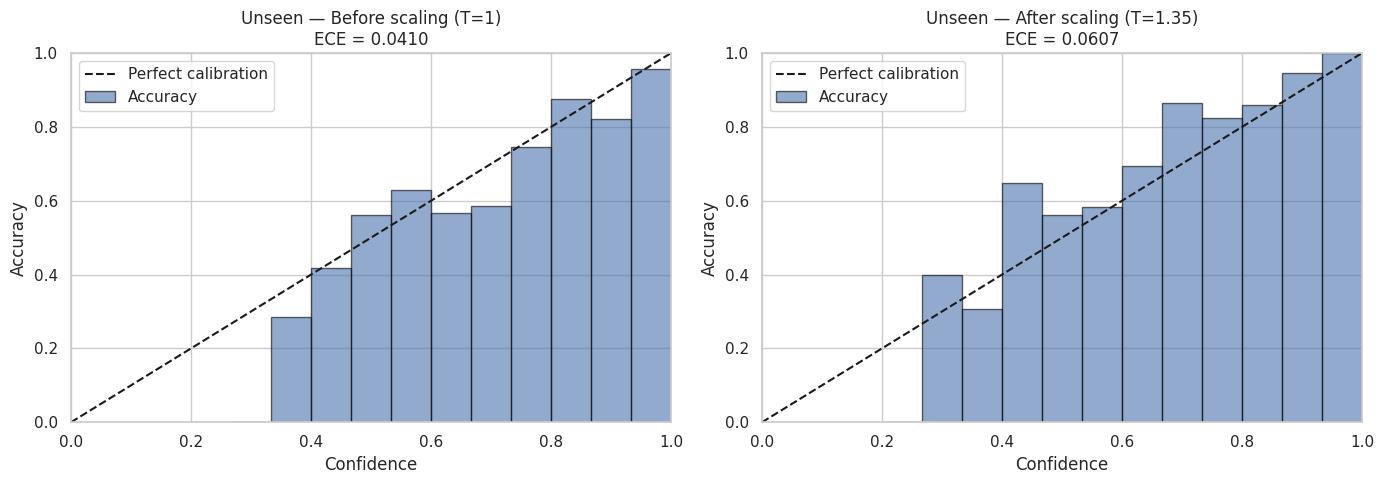

Saved calibration_unseen.png


In [28]:
# PART 9.1 — reliability diagram for unseen event
def plot_reliability(bin_data, ece, title, ax):
    filled = [b for b in bin_data if b["n"] > 0]
    mids = [(b["lo"] + b["hi"]) / 2 for b in filled]
    accs = [b["acc"] for b in filled]
    ax.bar(mids, accs, width=1.0/15, alpha=0.6, edgecolor="black", label="Accuracy")
    ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
    ax.set(xlim=(0,1), ylim=(0,1), xlabel="Confidence", ylabel="Accuracy", title=f"{title}\nECE = {ece:.4f}")
    ax.legend(loc="upper left")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_reliability(bins_pre,  unseen_ece_pre,  "Unseen — Before scaling (T=1)", axes[0])
plot_reliability(bins_post, unseen_ece_post, f"Unseen — After scaling (T={T_frozen:.2f})", axes[1])
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "calibration_unseen.png"), dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved calibration_unseen.png")

## 10 — Selective Prediction on Unseen Event

In [29]:
# PART 10 — apply frozen tau and compare coverage/risk: seen vs unseen
def selective_stats(probs, labels, tau):
    confs = probs.max(axis=1)
    preds = probs.argmax(axis=1)
    accepted = confs >= tau
    coverage = accepted.mean()
    risk = 1.0 - (preds[accepted] == labels[accepted]).mean() if accepted.any() else 0.0
    return float(coverage), float(risk)


seen_probs_post = softmax_with_temperature(seen_logits, T_frozen)
seen_cov,   seen_risk   = selective_stats(seen_probs_post, seen_labels, TAU_frozen)
unseen_cov, unseen_risk = selective_stats(unseen_probs_post, unseen_labels, TAU_frozen)

print(f"{'Metric':<25} {'Seen test':>12} {'Unseen held':>15}")
print("-" * 55)
print(f"{'Coverage':<25} {seen_cov:>12.2%} {unseen_cov:>15.2%}")
print(f"{'Risk':<25} {seen_risk:>12.4f} {unseen_risk:>15.4f}")
print(f"{'Review rate':<25} {1-seen_cov:>12.2%} {1-unseen_cov:>15.2%}")

Metric                       Seen test     Unseen held
-------------------------------------------------------
Coverage                        33.32%          36.84%
Risk                            0.0257          0.0105
Review rate                     66.68%          63.16%


**10 Explanation**

- Frozen tau was chosen on validation in NB2 to keep risk below 5%.
- On unseen events, coverage drops and review rate rises. This is intended: the model is less certain on unfamiliar data, routing more samples to human review.
- If unseen risk remains elevated despite higher review rates, the distribution shift is severe enough that even confident predictions are unreliable.

## 11 — Save Predictions and Per-Event Summary

In [30]:
# PART 11 — write prediction CSV and per-event JSON
unseen_confs = unseen_probs_post.max(axis=1)
pred_df = pd.DataFrame({
    "true_label":      [LABELS[l] for l in unseen_labels],
    "predicted_label": [LABELS[p] for p in unseen_probs_post.argmax(axis=1)],
    **{f"prob_{lab}": unseen_probs_post[:, i] for i, lab in enumerate(LABELS)},
    "confidence":      unseen_confs,
    "needs_review":    unseen_confs < TAU_frozen,
})
pred_path = os.path.join(PRED_DIR, f"{HELD_OUT_EVENT}_predictions.csv")
pred_df.to_csv(pred_path, index=False)
print(f"{'Predictions':<25} {pred_df.shape}")
print(f"{'needs_review':<25} {pred_df['needs_review'].sum()} ({pred_df['needs_review'].mean():.1%})")

per_event = {
    HELD_OUT_EVENT: {
        "samples":     len(unseen_labels),
        "macro_f1":    round(float(unseen_f1), 4),
        "ece_before":  round(unseen_ece_pre, 4),
        "ece_after":   round(unseen_ece_post, 4),
        "coverage":    round(unseen_cov, 4),
        "risk":        round(unseen_risk, 4),
        "review_rate": round(1 - unseen_cov, 4),
    }
}
with open(os.path.join(RESULTS_DIR, "per_event_f1.json"), "w") as f:
    json.dump(per_event, f, indent=2)
print(f"Saved per_event_f1.json")

Predictions               (779, 14)
needs_review              492 (63.2%)
Saved per_event_f1.json


## Conclusion

In [31]:
print("Notebook 3 complete: Cross-Event Evaluation (Regime B)")
print("=" * 60)
print(f"{'Held-out event':<30} {HELD_OUT_EVENT}")
print(f"{'Best encoder (unseen)':<30} {best_enc}")
print(f"{'Seen macro-F1':<30} {seen_f1:.4f}")
print(f"{'Unseen macro-F1':<30} {unseen_f1:.4f}")
print(f"{'F1 drop':<30} {seen_f1 - unseen_f1:.4f}")
print(f"{'ECE unseen (before)':<30} {unseen_ece_pre:.4f}")
print(f"{'ECE unseen (after)':<30} {unseen_ece_post:.4f}")
print(f"{'Coverage (tau={TAU_frozen:.3f})':<30} {unseen_cov:.2%}")
print(f"{'Risk':<30} {unseen_risk:.4f}")
print(f"{'Review rate':<30} {1-unseen_cov:.2%}")

Notebook 3 complete: Cross-Event Evaluation (Regime B)
Held-out event                 cyclone_idai_2019
Best encoder (unseen)          twitter-roberta-base
Seen macro-F1                  0.7664
Unseen macro-F1                0.7182
F1 drop                        0.0482
ECE unseen (before)            0.0410
ECE unseen (after)             0.0607
Coverage (tau={TAU_frozen:.3f}) 36.84%
Risk                           0.0105
Review rate                    63.16%
